In [23]:
import pandas as pd

In [24]:
data = pd.read_csv("../../../data/votable_supply-dhruvi/data/all_parameters.csv")

In [25]:
data.head()

,Date,OP_Price,OP_Price_Scaled,AVPI,PR,LAR,LAR_Scaled,PSI,PSI_Scaled,VPI,Votable Supply,Circulating Supply,F,Videal,OP_Token_Balance
0,2023-12-04,1.719741,0.261909,0.000833,0.090822,0.093632,0.278700,1.000000,0.495454,0.970289,82765569.72,911294948.0,12.476,2.347364e+08,1.756982e+08
1,2023-12-05,1.790326,0.282886,0.000369,0.090529,0.330732,0.558378,0.980287,0.456141,0.428071,82498452.48,911294948.0,11.881,2.261250e+08,1.776718e+08
2,2023-12-06,1.800778,0.286077,0.000374,0.091018,0.202520,0.399757,0.983065,0.461659,0.436652,82944352.75,911294948.0,11.619,2.238701e+08,1.774547e+08
3,2023-12-07,1.712827,0.259909,0.000380,0.090122,0.196524,0.392585,1.025158,0.545643,0.438521,82127363.78,911294948.0,12.672,2.355019e+08,1.776678e+08
4,2023-12-08,2.178050,0.413721,0.000286,0.090156,0.542970,0.785123,0.844951,0.221219,0.330085,82158482.04,911294948.0,8.608,1.821684e+08,1.806733e+08


In [26]:
data.tail()

,Date,OP_Price,OP_Price_Scaled,AVPI,PR,LAR,LAR_Scaled,PSI,PSI_Scaled,VPI,Votable Supply,Circulating Supply,F,Videal,OP_Token_Balance
358,2024-11-26,2.306790,0.461204,0.006816,0.083130,0.951899,0.965790,0.893687,0.295527,0.163638,104333549.2,1.255070e+09,7.941,2.202022e+08,3.166660e+08
359,2024-11-27,2.200223,0.421810,0.006601,0.083056,0.672305,0.874621,0.965474,0.426929,0.158348,104240738.0,1.255070e+09,8.521,2.296799e+08,3.146928e+08
360,2024-11-28,2.484551,0.527758,0.006429,0.082673,0.685833,0.881852,0.902667,0.310701,0.153503,103760796.7,1.255070e+09,7.033,2.039190e+08,3.165531e+08
361,2024-11-29,2.362092,0.481872,0.006288,0.082617,0.648922,0.861228,0.965805,0.427577,0.150046,103690143.2,1.255070e+09,7.586,2.129547e+08,3.187955e+08
362,2024-11-30,2.385789,0.490752,0.006250,0.082948,0.375852,0.613058,0.967300,0.430506,0.149728,104105543.4,1.255070e+09,7.331,2.095603e+08,3.184208e+08


### Correlation of all parameters with Videal

In [27]:
# Drop the non-numeric 'Date' column
numeric_data = data.drop(columns=["Date"])

# Compute correlation with Videal
correlation_with_videal = numeric_data.corr()["Videal"].sort_values(ascending=False)

# Display the correlations
print(correlation_with_videal)

Videal                1.000000
F                     0.984785
Circulating Supply    0.841453
OP_Token_Balance      0.783964
Votable Supply        0.696802
VPI                   0.640879
AVPI                  0.441622
PSI                   0.145461
PSI_Scaled            0.141639
LAR                  -0.299996
LAR_Scaled           -0.334197
PR                   -0.585214
OP_Price             -0.885772
OP_Price_Scaled      -0.907699
Name: Videal, dtype: float64


### Predict Videal

In [28]:
data = pd.read_csv("../../../data/votable_supply-dhruvi/data/all_parameters.csv")

In [29]:
data.columns

Index(['Date', 'OP_Price', 'OP_Price_Scaled', 'AVPI', 'PR', 'LAR',
       'LAR_Scaled', 'PSI', 'PSI_Scaled', 'VPI', 'Votable Supply',
       'Circulating Supply', 'F', 'Videal', 'OP_Token_Balance'],
      dtype='object')

In [30]:
data = data.drop(columns=["OP_Price", "LAR", "PSI", "OP_Token_Balance"])

### Linear Regression

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_20224\2830193786.py:50: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data['Predicted_Videal'] = y_pred


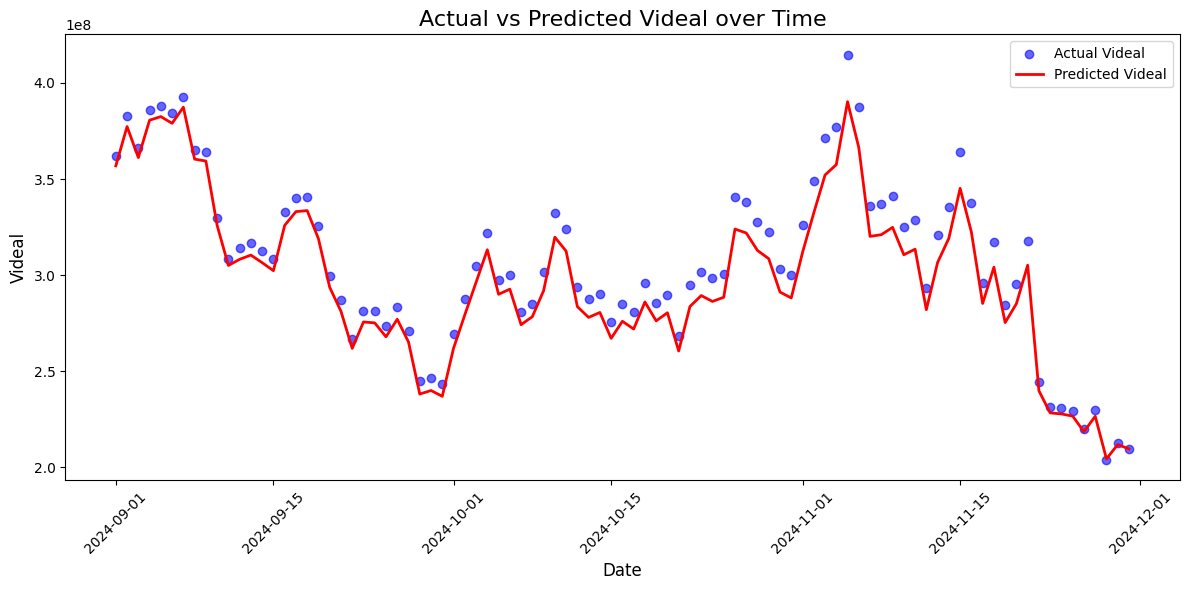

Coefficients of the model: [ 1.40745729e+07  1.16761808e+07 -2.34068843e+09 -2.41106440e+06
 -2.88979518e+06 -7.67013504e+06  2.21435553e+07 -1.55649288e+07
  7.05770738e+07]
Mean Absolute Error (MAE): 9211885.0058
Mean Squared Error (MSE): 109059160346497.2500
Root Mean Squared Error (RMSE): 10443139.3913
R² Score: 0.9457


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Step 1: Prepare the data
# Convert the 'Date' column to datetime for filtering
data['Date'] = pd.to_datetime(data['Date'])

# Split the data into training and testing based on the date range
train_data = data[(data['Date'] >= "2023-12-04") & (data['Date'] <= "2024-08-31")]
test_data = data[(data['Date'] >= "2024-09-01") & (data['Date'] <= "2024-11-30")]

# Separate features and target variable
X_train = train_data.drop(columns=["Date", "Videal"])
y_train = train_data["Videal"]

X_test = test_data.drop(columns=["Date", "Videal"])
y_test = test_data["Videal"]

# Step 2: Scale the OP_Token_Balance column only
scaler = StandardScaler()

# Scale OP_Token_Balance for both training and testing
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled['Votable Supply'] = scaler.fit_transform(X_train[['Votable Supply']])
X_test_scaled['Votable Supply'] = scaler.transform(X_test[['Votable Supply']])

X_train_scaled['Circulating Supply'] = scaler.fit_transform(X_train[['Circulating Supply']])
X_test_scaled['Circulating Supply'] = scaler.transform(X_test[['Circulating Supply']])

X_train_scaled['F'] = scaler.fit_transform(X_train[['F']])
X_test_scaled['F'] = scaler.transform(X_test[['F']])

# Step 3: Train the Linear Regression model
# Initialize the model
lr_model = LinearRegression()

# Train the model on the scaled training data
lr_model.fit(X_train_scaled, y_train)

# Step 4: Evaluate the model
# Predict on the scaled test data
y_pred = lr_model.predict(X_test_scaled)

# Add predictions to the test data for visualization
test_data['Predicted_Videal'] = y_pred

# Sort the test data by the 'Date' column
test_data = test_data.sort_values(by='Date')

# Plotting
plt.figure(figsize=(12, 6))

# Scatter plot for actual 'Videal'
plt.scatter(test_data['Date'], test_data['Videal'], color='blue', label='Actual Videal', alpha=0.6)

# Line plot for predicted 'Videal'
plt.plot(test_data['Date'], test_data['Predicted_Videal'], color='red', label='Predicted Videal', linewidth=2)

# Add labels and title
plt.title('Actual vs Predicted Videal over Time', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Videal', fontsize=12)
plt.legend()

# Display the plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Coefficients of the model
print("Coefficients of the model:", lr_model.coef_)

# Calculate error metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

# Display results
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")


### Polynomial Regression

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_20224\2501693286.py:57: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data['Predicted_Videal_Poly'] = y_pred_poly


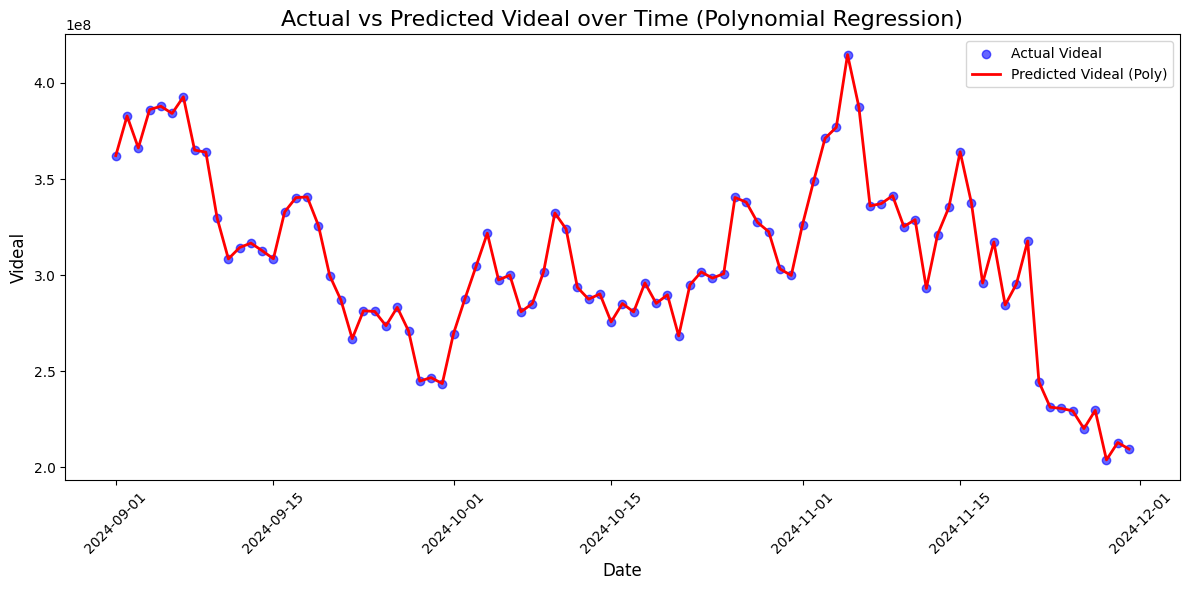

Coefficients of the Polynomial model: [ 4.17805625e+05 -3.05213034e-05 -3.71020287e-04 -2.45056394e-02
 -6.72414899e-06 -8.56025144e-06  4.67635691e-05  1.18053685e+07
 -1.68139115e-04  6.45631926e+07 -1.45565718e-06 -4.55044210e-06
  3.50149348e-04  2.27801502e-06  1.04866922e-06 -3.19909304e-06
 -9.14558768e-07  2.07591802e-06 -5.62053174e-07 -1.49505213e-05
  4.79101203e-03 -3.68803740e-06 -9.56095755e-06 -7.11064786e-05
 -2.12602317e-05  2.81892717e-05  2.72877514e-06  1.32044594e-01
  8.34269449e-05  8.96230340e-05 -4.81133815e-04 -1.36713218e-03
  1.81005499e-03 -1.44171529e-04 -1.55158341e-06  1.01327896e-06
 -8.15838575e-07 -6.99888915e-07  1.22422352e-06 -1.37020834e-07
 -1.18277967e-07  4.00003046e-07 -2.83122063e-07  1.27381645e-06
 -1.73225999e-07 -4.57279384e-06  7.80425034e-06 -5.67408279e-06
  3.10223550e-06  3.21562402e-06 -1.00317411e-05  3.95745273e+06
  7.38480594e-06 -1.09151006e-06  4.44706529e-08]
Mean Absolute Error (MAE) for Polynomial Regression: 0.0000
Mean Sq

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Step 1: Prepare the data
# Convert the 'Date' column to datetime for filtering
data['Date'] = pd.to_datetime(data['Date'])

# Split the data into training and testing based on the date range
train_data = data[(data['Date'] >= "2023-12-04") & (data['Date'] <= "2024-08-31")]
test_data = data[(data['Date'] >= "2024-09-01") & (data['Date'] <= "2024-12-31")]

# Separate features and target variable
X_train = train_data.drop(columns=["Date", "Videal"])
y_train = train_data["Videal"]

X_test = test_data.drop(columns=["Date", "Videal"])
y_test = test_data["Videal"]

# Step 2: Scale the OP_Token_Balance column only
scaler = StandardScaler()

# Scale OP_Token_Balance for both training and testing
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled['Votable Supply'] = scaler.fit_transform(X_train[['Votable Supply']])
X_test_scaled['Votable Supply'] = scaler.transform(X_test[['Votable Supply']])

X_train_scaled['Circulating Supply'] = scaler.fit_transform(X_train[['Circulating Supply']])
X_test_scaled['Circulating Supply'] = scaler.transform(X_test[['Circulating Supply']])

X_train_scaled['F'] = scaler.fit_transform(X_train[['F']])
X_test_scaled['F'] = scaler.transform(X_test[['F']])

# Step 3: Apply Polynomial Transformation (you can adjust the degree)
poly = PolynomialFeatures(degree = 2)

# Transform features into polynomial features
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

# Step 4: Train the Polynomial Regression model
# Initialize the model
poly_lr_model = LinearRegression()

# Train the model on the polynomial transformed training data
poly_lr_model.fit(X_train_poly, y_train)

# Step 5: Evaluate the model
# Predict on the transformed test data
y_pred_poly = poly_lr_model.predict(X_test_poly)

# Add predictions to the test data for visualization
test_data['Predicted_Videal_Poly'] = y_pred_poly

# Sort the test data by the 'Date' column
test_data = test_data.sort_values(by='Date')

# Plotting for Polynomial Regression
plt.figure(figsize=(12, 6))

# Scatter plot for actual 'Videal'
plt.scatter(test_data['Date'], test_data['Videal'], color='blue', label='Actual Videal', alpha=0.6)

# Line plot for predicted 'Videal' using Polynomial Regression
plt.plot(test_data['Date'], test_data['Predicted_Videal_Poly'], color='red', label='Predicted Videal (Poly)', linewidth=2)

# Add labels and title
plt.title('Actual vs Predicted Videal over Time (Polynomial Regression)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Videal', fontsize=12)
plt.legend()

# Display the plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Coefficients of the polynomial model
print("Coefficients of the Polynomial model:", poly_lr_model.coef_)

# Calculate error metrics
mae_poly = mean_absolute_error(y_test, y_pred_poly)
mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = mse_poly ** 0.5
r2_poly = r2_score(y_test, y_pred_poly)

# Display results
print(f"Mean Absolute Error (MAE) for Polynomial Regression: {mae_poly:.4f}")
print(f"Mean Squared Error (MSE) for Polynomial Regression: {mse_poly:.4f}")
print(f"Root Mean Squared Error (RMSE) for Polynomial Regression: {rmse_poly:.4f}")
print(f"R² Score for Polynomial Regression: {r2_poly:.4f}")


### LSTM

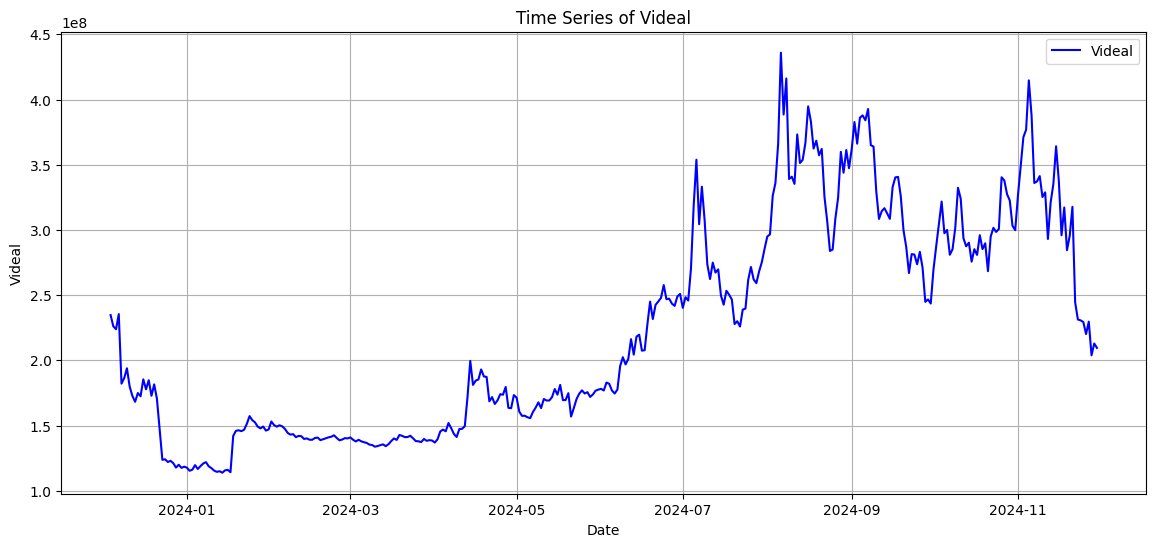

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv("../../../data/votable_supply-dhruvi/data/all_parameters.csv")

# Convert 'Date' to datetime format
data['Date'] = pd.to_datetime(data['Date'])

# Drop rows with missing 'Date' or 'Videal'
data = data.dropna(subset=['Date', 'Videal'])

# Sort the data by date to ensure correct time-series order
data = data.sort_values('Date')

# Plot the time series of Videal
plt.figure(figsize=(14, 6))
plt.plot(data['Date'], data['Videal'], label='Videal', color='blue')
plt.title('Time Series of Videal')
plt.xlabel('Date')
plt.ylabel('Videal')
plt.grid(True)
plt.legend()
plt.show()

Testing: units=50, dropout_rate=0.2, learning_rate=0.001


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 221ms/step
R² Score: 0.6853
Testing: units=50, dropout_rate=0.2, learning_rate=0.0005


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
R² Score: 0.7377
Testing: units=50, dropout_rate=0.3, learning_rate=0.001


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (7 outputs left out)

c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
R² Score: 0.6912
Testing: units=100, dropout_rate=0.3, learning_rate=0.0005


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
R² Score: 0.7504
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Best Model Performance:
Mean Absolute Error (MAE): 15806616.4576
Mean Squared Error (MSE): 358846098578270.1875
Root Mean Squared Error (RMSE): 18943233.5830
R² Score: 0.7929


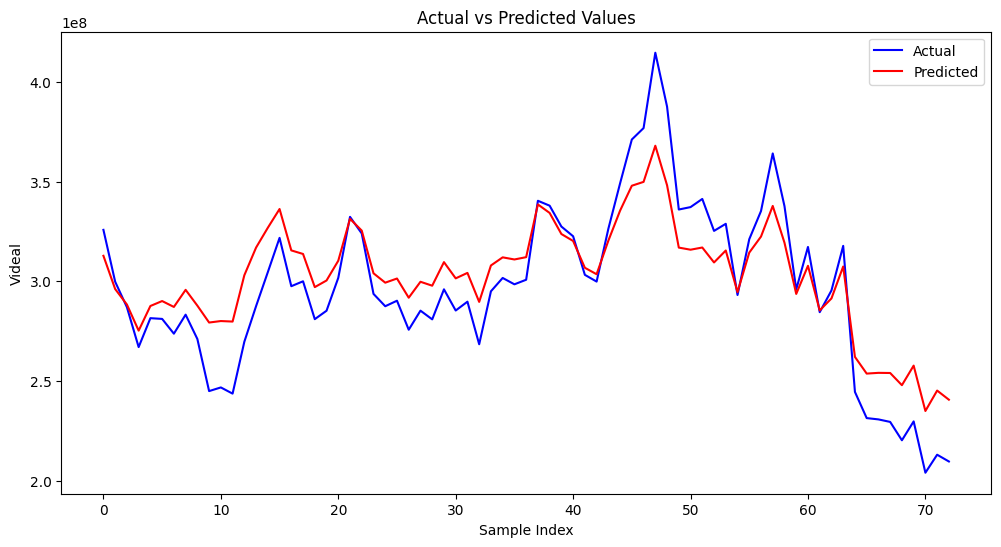

In [34]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

data = pd.read_csv("../../../data/votable_supply-dhruvi/data/all_parameters.csv")

data['Date'] = pd.to_datetime(data['Date'])

# Select relevant columns
columns_to_use = ['Date', 'OP_Price_Scaled', 'AVPI', 'PR', 'LAR_Scaled', 'PSI_Scaled', 'VPI', 
                  'Votable Supply', 'Circulating Supply', 'F', 'Videal']
df_selected = data[columns_to_use]

# Sort the data by 'Date'
df_selected = df_selected.sort_values('Date')
df_selected = df_selected.drop('Date', axis=1)

# Identify unscaled features and target
unscaled_features = ['Votable Supply', 'Circulating Supply', 'F']
target_column = 'Videal'

# Scale features and target
scaler_features = MinMaxScaler(feature_range=(0, 1))
scaler_target = MinMaxScaler(feature_range=(0, 1))
df_selected[unscaled_features] = scaler_features.fit_transform(df_selected[unscaled_features])
df_selected[target_column] = scaler_target.fit_transform(df_selected[[target_column]])

# Split features (X) and target (y)
X = df_selected.drop(target_column, axis=1)
y = df_selected[target_column]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Reshape for LSTM input
X_train_lstm = X_train.values.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_lstm = X_test.values.reshape((X_test.shape[0], 1, X_test.shape[1]))
y_train = y_train.values.reshape(-1, 1)
y_test = y_test.values.reshape(-1, 1)

# Define the LSTM model
def build_model(units=50, dropout_rate=0.2, learning_rate=0.001):
    model = Sequential()
    model.add(LSTM(units=units, activation='relu', return_sequences=False, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))
    model.add(Dropout(dropout_rate))
    model.add(Dense(units=1))  # Output layer
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mean_squared_error')
    return model

# Early stopping and learning rate scheduler
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-5)

# Hyperparameter tuning
best_r2 = -np.inf
best_model = None
for units in [50, 100]:
    for dropout_rate in [0.2, 0.3]:
        for learning_rate in [0.001, 0.0005]:
            print(f"Testing: units={units}, dropout_rate={dropout_rate}, learning_rate={learning_rate}")
            model = build_model(units=units, dropout_rate=dropout_rate, learning_rate=learning_rate)
            history = model.fit(X_train_lstm, y_train, epochs=50, batch_size=32, 
                                validation_split=0.1, callbacks=[early_stop, reduce_lr], verbose=0)
            
            # Evaluate model
            y_pred = model.predict(X_test_lstm)
            y_pred_original = scaler_target.inverse_transform(y_pred)
            y_test_original = scaler_target.inverse_transform(y_test)
            r2 = r2_score(y_test_original, y_pred_original)
            print(f"R² Score: {r2:.4f}")
            
            if r2 > best_r2:
                best_r2 = r2
                best_model = model

# Evaluate the best model
y_pred = best_model.predict(X_test_lstm)
y_pred_original = scaler_target.inverse_transform(y_pred)
y_test_original = scaler_target.inverse_transform(y_test)

mae = mean_absolute_error(y_test_original, y_pred_original)
mse = mean_squared_error(y_test_original, y_pred_original)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_original, y_pred_original)

print(f"Best Model Performance:")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(y_test_original, label='Actual', color='blue')
plt.plot(y_pred_original, label='Predicted', color='red')
plt.title('Actual vs Predicted Values')
plt.xlabel('Sample Index')
plt.ylabel('Videal')
plt.legend()
plt.show()


### Predict

Epoch 1/50


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - loss: 0.1328 - val_loss: 0.2777 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1117 - val_loss: 0.2081 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0845 - val_loss: 0.1418 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0529 - val_loss: 0.0896 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0444 - val_loss: 0.0503 - learning_rate: 0.0010
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0321 - val_loss: 0.0314 - learning_rate: 0.0010
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0222 - val_loss: 0.0240 - learning_rate: 0.0010
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0173 - val_loss: 0.0163 - learning_rate: 0.0010
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0125 - val_loss: 0.0117 - learning_rate: 0.0010
Epoch 10/50
11/11 ━━━━━━━━━━━━

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_20224\790936573.py:69: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data_selected[unscaled_features] = scaler_features.transform(test_data_selected[unscaled_features])


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


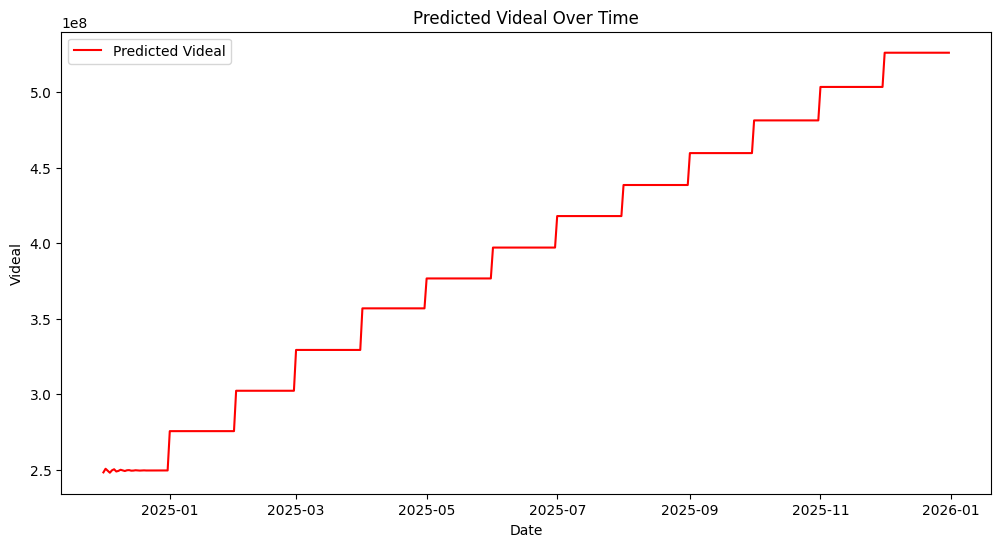

In [35]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt

# Load and preprocess the data
data = pd.read_csv("../../../data/votable_supply-dhruvi/data/all_parameters.csv")

# Convert 'Date' to datetime
data['Date'] = pd.to_datetime(data['Date'])

# Select relevant columns
columns_to_use = ['Date', 'OP_Price_Scaled', 'AVPI', 'PR', 'LAR_Scaled', 'PSI_Scaled', 'VPI', 
                  'Votable Supply', 'Circulating Supply', 'F', 'Videal']
df_selected = data[columns_to_use]

# Sort the data by 'Date'
df_selected = df_selected.sort_values('Date')
df_selected = df_selected.drop('Date', axis=1)

# Identify unscaled features and target
unscaled_features = ['Votable Supply', 'Circulating Supply', 'F']
target_column = 'Videal'

# Scale features and target
scaler_features = MinMaxScaler(feature_range=(0, 1))
scaler_target = MinMaxScaler(feature_range=(0, 1))
df_selected[unscaled_features] = scaler_features.fit_transform(df_selected[unscaled_features])
df_selected[target_column] = scaler_target.fit_transform(df_selected[[target_column]])

# Split features (X) and target (y)
X = df_selected.drop(target_column, axis=1)
y = df_selected[target_column]

# Reshape for LSTM input
X_lstm = X.values.reshape((X.shape[0], 1, X.shape[1]))
y = y.values.reshape(-1, 1)

# Define the LSTM model
def build_model(units=50, dropout_rate=0.3, learning_rate=0.0005):
    model = Sequential()
    model.add(LSTM(units=units, activation='relu', return_sequences=False, input_shape=(X_lstm.shape[1], X_lstm.shape[2])))
    model.add(Dropout(dropout_rate))
    model.add(Dense(units=1))  # Output layer
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mean_squared_error')
    return model

# Early stopping and learning rate scheduler
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-5)

# Train the model on the entire dataset
model = build_model(units=50, dropout_rate=0.2, learning_rate=0.001)
history = model.fit(X_lstm, y, epochs=50, batch_size=32, validation_split=0.1, callbacks=[early_stop, reduce_lr], verbose=1)

# Load the predicted data
test_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/parameters_predicted_data.csv")  # Replace with the path of your predicted data

# Preprocess the test data
test_data['Date'] = pd.to_datetime(test_data['Date'])
test_data_selected = test_data[['Date', 'OP_Price_Scaled', 'AVPI', 'PR', 'LAR_Scaled', 'PSI_Scaled', 'VPI', 
                                'Votable Supply', 'Circulating Supply', 'F']]

# Scale the features in the test data using the previously fitted scalers
test_data_selected[unscaled_features] = scaler_features.transform(test_data_selected[unscaled_features])

# Prepare the input features for prediction
X_test_lstm = test_data_selected.drop('Date', axis=1).values.reshape((test_data_selected.shape[0], 1, test_data_selected.shape[1]-1))

# Predict 'Videal' on the test data
y_pred = model.predict(X_test_lstm)

# Inverse transform the predictions to original scale
y_pred_original = scaler_target.inverse_transform(y_pred)

# Add the predictions to the test_data dataframe
test_data['Videal_Predicted'] = y_pred_original

# Save the predictions to a new CSV file
test_data.to_csv("../../../data/votable_supply-dhruvi/data/videal_predicted.csv", index=False)

# Plot the predicted values
plt.figure(figsize=(12, 6))
plt.plot(test_data['Date'], test_data['Videal_Predicted'], label='Predicted Videal', color='red')
plt.title('Predicted Videal Over Time')
plt.xlabel('Date')
plt.ylabel('Videal')
plt.legend()
plt.show()
